<p style="color: #05402B; font-size: 32px; font-weight: bold; text-align: center; margin-top: 20px;"> 
Restaurants in Madrid
</p>
<p style="color: #000000; font-size: 24px; text-align: center; margin-bottom: 20px;">
A review analysis system for restaurant diagnosis and competitive benchmarking
</p>


# 1. Understanding the data and initial exploration


## Import libraries


In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import pandera.pandas as pa

## 1.1. Load the data


In [2]:
# Load the original data
DATA_PATH = Path('data')

reviews_df = pd.read_pickle(DATA_PATH / 'reviews.pkl')
items_df = pd.read_pickle(DATA_PATH / 'items.pkl')


In [3]:
# Convert column names to snake_case
for df in [reviews_df, items_df]:
    df.columns = df.columns.str.replace(
        r"(?<!^)(?=[A-Z])", "_", regex=True
    ).str.lower()

In [4]:
# Display sample rows
display(reviews_df.head())
display(items_df.head())

,review_id,user_id,item_id,title,text,date,rating,language,images,url
0,881374404,74B2D6F62DB1CEC358822079728F8317,20112202,Cena en familia,"Pedimos una pizza para cenar, mitad barbacoa m...",2023-03-07,50,es,[https://media-cdn.tripadvisor.com/media/photo...,https://www.tripadvisor.com/ShowUserReviews-g1...
1,872226520,1B3559478B9FF8A52A552BA99AC6F00E,20112202,Que asco de restaurante,"Better pizza, mejor ponte a hacer pan que tien...",2022-12-19,10,es,[],https://www.tripadvisor.com/ShowUserReviews-g1...
2,850451467,FE5E99DC6572BB56B2D1D893BC13A392,20112202,"Pizzas distintas, riquísimas","Pizza de rabo de toro, conejo al ajillo,... so...",2022-07-28,50,es,[https://media-cdn.tripadvisor.com/media/photo...,https://www.tripadvisor.com/ShowUserReviews-g1...
3,810574583,9E85C6C3DA1C0498B1EEEE9A3A833A99,20112202,ONE OF THE BEST PIZZAS,"pizza rica y distinta. calidad muy alta, el sa...",2021-09-18,50,es,[],https://www.tripadvisor.com/ShowUserReviews-g1...
4,757187287,5FB02D459F27ECD91CB38AC3CCD92B79,20112202,Muy buenas pizzas. Tienen,Muy buenas pizzas. Tienen de varios tamaños pe...,2020-06-10,50,es,[],https://www.tripadvisor.com/ShowUserReviews-g1...


,item_id,name,city,price_interval,url,rating,type
0,20112202,66's Bar&pizzas,Madrid,$$ - $$$,https://www.tripadvisor.com/Restaurant_Review-...,45,"[Italian, Pizza]"
1,17763117,80's Coffee,Madrid,,https://www.tripadvisor.com/Restaurant_Review-...,20,"[Coffee & Tea, Cafe]"
2,11859217,84,Madrid,$$ - $$$,https://www.tripadvisor.com/Restaurant_Review-...,45,"[Mediterranean, Spanish]"
3,11862880,A' La Broaster,Madrid,$,https://www.tripadvisor.com/Restaurant_Review-...,50,[Fast Food]
4,10276639,A' Lareira,Madrid,,https://www.tripadvisor.com/Restaurant_Review-...,30,[Spanish]


## 1.2. Describe the datasets


<h2 style="color:#05402B; text-align:center;">Data dictionary</h2>

<table width="100%" border="0" cellspacing="0" cellpadding="0" style="width:100%; border:none; border-collapse:collapse; margin-bottom:30px;">
<tr>
<td width="47%" style="width:47%; padding:0; vertical-align:top; border:none;">
<table width="100%" cellspacing="0" cellpadding="0" style="width:100%; border-collapse:collapse;">
<thead>
<tr>
<th colspan="2" style="padding:12px; background-color:#05402B; color:white; text-align:left; border:1px solid #2F75B5;">Review Information</th>
</tr>
<tr style="background-color:#D9EAF7;">
<th style="width:27%; padding:9px; text-align:left; border:1px solid #B4C6E7;">Variable</th>
<th style="padding:9px; text-align:left; border:1px solid #B4C6E7;">Description</th>
</tr>
</thead>
<tbody>
<tr style="background-color:#FFFFFF;">
<td style="padding:9px; border:1px solid #B4C6E7;"><strong>review_id</strong></td>
<td style="padding:9px; border:1px solid #B4C6E7;">Unique identifier for each review.</td>
</tr>
<tr style="background-color:#F2F6FA;">
<td style="padding:9px; border:1px solid #B4C6E7;"><strong>user_id</strong></td>
<td style="padding:9px; border:1px solid #B4C6E7;">Identifier of the user who wrote the review.</td>
</tr>
<tr style="background-color:#FFFFFF;">
<td style="padding:9px; border:1px solid #B4C6E7;"><strong>item_id</strong></td>
<td style="padding:9px; border:1px solid #B4C6E7;">Identifier of the restaurant associated with the review.</td>
</tr>
<tr style="background-color:#F2F6FA;">
<td style="padding:9px; border:1px solid #B4C6E7;"><strong>title</strong></td>
<td style="padding:9px; border:1px solid #B4C6E7;">Title summarizing the user's opinion.</td>
</tr>
<tr style="background-color:#FFFFFF;">
<td style="padding:9px; border:1px solid #B4C6E7;"><strong>text</strong></td>
<td style="padding:9px; border:1px solid #B4C6E7;">Full text describing the user's experience.</td>
</tr>
<tr style="background-color:#F2F6FA;">
<td style="padding:9px; border:1px solid #B4C6E7;"><strong>date</strong></td>
<td style="padding:9px; border:1px solid #B4C6E7;">Date when the review was published.</td>
</tr>
<tr style="background-color:#FFFFFF;">
<td style="padding:9px; border:1px solid #B4C6E7;"><strong>rating</strong></td>
<td style="padding:9px; border:1px solid #B4C6E7;">Rating from 0 to 50, where 50 represents the highest satisfaction.</td>
</tr>
<tr style="background-color:#F2F6FA;">
<td style="padding:9px; border:1px solid #B4C6E7;"><strong>language</strong></td>
<td style="padding:9px; border:1px solid #B4C6E7;">Language in which the review was written.</td>
</tr>
<tr style="background-color:#FFFFFF;">
<td style="padding:9px; border:1px solid #B4C6E7;"><strong>images</strong></td>
<td style="padding:9px; border:1px solid #B4C6E7;">List of URLs pointing to images uploaded by the user, when available.</td>
</tr>
<tr style="background-color:#F2F6FA;">
<td style="padding:9px; border:1px solid #B4C6E7;"><strong>url</strong></td>
<td style="padding:9px; border:1px solid #B4C6E7;">Link to the full review on TripAdvisor.</td>
</tr>
</tbody>
</table>
</td>
<td width="6%" style="width:6%; padding:0; border:none; background-color:#FFFFFF;">&nbsp;</td>
<td width="47%" style="width:47%; padding:0; vertical-align:top; border:none;">
<table width="100%" cellspacing="0" cellpadding="0" style="width:100%; border-collapse:collapse;">
<thead>
<tr>
<th colspan="2" style="padding:12px; background-color:#05402B; color:white; text-align:left; border:1px solid #2F75B5;">Restaurant Information (Items)</th>
</tr>
<tr style="background-color:#D9EAF7;">
<th style="width:30%; padding:9px; text-align:left; border:1px solid #B4C6E7;">Variable</th>
<th style="padding:9px; text-align:left; border:1px solid #B4C6E7;">Description</th>
</tr>
</thead>
<tbody>
<tr style="background-color:#FFFFFF;">
<td style="padding:9px; border:1px solid #B4C6E7;"><strong>item_id</strong></td>
<td style="padding:9px; border:1px solid #B4C6E7;">Unique identifier for each restaurant.</td>
</tr>
<tr style="background-color:#F2F6FA;">
<td style="padding:9px; border:1px solid #B4C6E7;"><strong>name</strong></td>
<td style="padding:9px; border:1px solid #B4C6E7;">Restaurant name.</td>
</tr>
<tr style="background-color:#FFFFFF;">
<td style="padding:9px; border:1px solid #B4C6E7;"><strong>city</strong></td>
<td style="padding:9px; border:1px solid #B4C6E7;">City where the restaurant is located.</td>
</tr>
<tr style="background-color:#F2F6FA;">
<td style="padding:9px; border:1px solid #B4C6E7;"><strong>price_interval</strong></td>
<td style="padding:9px; border:1px solid #B4C6E7;">Restaurant price range.</td>
</tr>
<tr style="background-color:#FFFFFF;">
<td style="padding:9px; border:1px solid #B4C6E7;"><strong>url</strong></td>
<td style="padding:9px; border:1px solid #B4C6E7;">Link to the restaurant's TripAdvisor page.</td>
</tr>
<tr style="background-color:#F2F6FA;">
<td style="padding:9px; border:1px solid #B4C6E7;"><strong>rating</strong></td>
<td style="padding:9px; border:1px solid #B4C6E7;">Average rating received by the restaurant.</td>
</tr>
<tr style="background-color:#FFFFFF;">
<td style="padding:9px; border:1px solid #B4C6E7;"><strong>type</strong></td>
<td style="padding:9px; border:1px solid #B4C6E7;">List of cuisine types, such as [Spanish, Mediterranean].</td>
</tr>
</tbody>
</table>
</td>
</tr>
</table>

<table width="100%" cellspacing="0" cellpadding="0" style="width:100%; border-collapse:collapse;">
<thead>
<tr>
<th colspan="2" style="padding:12px; background-color:#05402B; color:white; text-align:left; border:1px solid #2F75B5;">User Information</th>
</tr>
<tr style="background-color:#D9EAF7;">
<th style="width:30%; padding:9px; text-align:left; border:1px solid #B4C6E7;">Variable</th>
<th style="padding:9px; text-align:left; border:1px solid #B4C6E7;">Description</th>
</tr>
</thead>
<tbody>
<tr style="background-color:#FFFFFF;">
<td style="padding:9px; border:1px solid #B4C6E7;"><strong>user_id</strong></td>
<td style="padding:9px; border:1px solid #B4C6E7;">Unique hashed identifier for each user.</td>
</tr>
<tr style="background-color:#F2F6FA;">
<td style="padding:9px; border:1px solid #B4C6E7;"><strong>name</strong></td>
<td style="padding:9px; border:1px solid #B4C6E7;">Display name or username.</td>
</tr>
<tr style="background-color:#FFFFFF;">
<td style="padding:9px; border:1px solid #B4C6E7;"><strong>location</strong></td>
<td style="padding:9px; border:1px solid #B4C6E7;">User's location, including city and country.</td>
</tr>
</tbody>
</table>

`User Information` is excluded because it does not support the project objective.

## 1.3. Variable types and roles


In [5]:
# Check data types
print(f"Review information")
reviews_df.info()
print(f"\nRestaurant information")
items_df.info()

Review information
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1347959 entries, 0 to 1347958
Data columns (total 10 columns):
 #   Column     Non-Null Count    Dtype 
---  ------     --------------    ----- 
 0   review_id  1347959 non-null  int64 
 1   user_id    1347959 non-null  object
 2   item_id    1347959 non-null  int64 
 3   title      1347959 non-null  object
 4   text       1347959 non-null  object
 5   date       1347959 non-null  object
 6   rating     1347959 non-null  int64 
 7   language   1347959 non-null  object
 8   images     1347959 non-null  object
 9   url        1347959 non-null  object
dtypes: int64(3), object(7)
memory usage: 102.8+ MB

Restaurant information
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 11544 entries, 0 to 11543
Data columns (total 7 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   item_id         11544 non-null  int64 
 1   name            11544 non-null  object
 2   city       

**Variable types and roles**

**Reviews**

- `review_id`, `user_id`, and `item_id`: identifiers stored as strings.
- `title` and `text`: text for natural language processing, stored as strings.
- `date`: date and time variable.
- `rating`: original score from 10 to 50.
- `language`: categorical variable.
- `images` and `url`: excluded variables.

**Items**

- `item_id`: string key used to join the datasets.
- `name`: restaurant name stored as a string.
- `price_interval`: categorical variable.
- `rating`: original score from 10 to 50.
- `type`: list of cuisine types stored as an object.
- `city` and `url`: excluded variables.


**Create copies for data cleaning**


We create copies, remove variables outside the project scope, clarify column names, and correct data types.


In [6]:
# Copy the datasets
# Remove unused columns
# Use clear rating names

reviews = (
    reviews_df
    .drop(columns=['images', 'url'])
    .rename(columns={'rating': 'review_rating'})
    .copy()
)


items = (
    items_df
    .drop(columns=['url', 'city'])
    .rename(columns={'rating': 'restaurant_rating'})
    .copy()
)

In [7]:
# Correct data types

# Reviews
reviews = reviews.astype({
    'review_id': 'string',
    'user_id': 'string',
    'item_id': 'string',
    'title': 'string',
    'text': 'string',
    'review_rating': 'Int64',
    'language': 'category'
})

reviews['date'] = pd.to_datetime(
    reviews['date'],
    format='%Y-%m-%d',
    errors='coerce'
)

# Items
items = items.astype({
    'item_id': 'string',
    'name': 'string',
    'price_interval': 'category',
    'restaurant_rating': 'Int64'
})

In [8]:
# Create a dictionary of DataFrames
datasets = {
    'reviews': reviews,
    'items': items
}

We correct data types before exploring the values. Section 2 covers data cleaning.


### Explore unique values


We check unique values to find invalid codes, out-of-range values, categories, duplicates, and missing data.


In [9]:
# Summarize unique values
unique_summary = []

# Examine each column
for dataset_name, dataframe in datasets.items():
    for column_name in dataframe.columns:
        values = dataframe[column_name].astype("string")
        value_counts = values.value_counts(dropna=False).sort_index()
        unique_summary.append({
            "dataset": dataset_name,
            "variable": column_name,
            "unique_values": values.nunique(dropna=True),
            "values": value_counts.to_dict()
        })

# Create a summary DataFrame
unique_summary = pd.DataFrame(unique_summary)
unique_summary

,dataset,variable,unique_values,values
0,reviews,review_id,1339351,"{'100002321': 1, '100002841': 1, '100005607': ..."
1,reviews,user_id,629201,"{'-1': 6123, '00001B21D9CFBF7BE3BFCC3FE152C4EC..."
2,reviews,item_id,10109,"{'10006904': 8, '10007089': 46, '10021151': 74..."
3,reviews,title,799215,"{'': 14, '!': 5, '! ALCACHOFAS AL PODER ¡': 1,..."
4,reviews,text,1338757,{'! If you are gluten free- this is the place ...
5,reviews,date,5562,"{'2002-11-11': 1, '2003-04-29': 1, '2003-10-12..."
6,reviews,review_rating,5,"{'10': 105657, '20': 72346, '30': 153771, '40'..."
7,reviews,language,27,"{'ar': 180, 'cs': 123, 'da': 1587, 'de': 9497,..."
8,items,item_id,11468,"{'10006904': 1, '10007089': 1, '10021151': 1, ..."
9,items,name,10327,"{'+Kcopas': 1, '+qdelicia': 1, '...hasta Los A..."


**Unique value review**

**Reviews**

- `review_id`: 8,608 IDs are reused; check them for duplicates.
- `user_id`: 6,123 records have `-1`, which means the user is unknown.
- `item_id`: values repeat because a restaurant can have many reviews.
- `title`: 14 empty entries.
- `text`: repeated text does not prove that entire rows are duplicates.
- `date`: 5,562 different dates; check the range and continuity.
- `review_rating`: scores of 10, 20, 30, 40, and 50.
- `language`: 27 languages; the selection is explained below.

**Items**

- `item_id`: 76 IDs are reused; each must be unique before the `many_to_one` merge.
- `name`: different restaurants may share a name.
- `price_interval`: 3,651 missing values.
- `restaurant_rating`: five out-of-range values of `-10` and 1,364 zeros to review.
- `type`: 825 combinations; use `explode()` to examine each cuisine type.


### Explore variables with charts


In [10]:
# Chart helpers
def format_axis(ax, title, xlabel='', ylabel='', grid_axis='y'):
    ax.set_title(title, fontsize=12, fontweight='bold', pad=20)
    ax.set_xlabel(xlabel, fontsize=11, fontweight='bold')
    ax.set_ylabel(ylabel, fontsize=11, fontweight='bold')
    ax.grid(axis=grid_axis, alpha=0.5)


def add_bar_labels(ax):
    for container in ax.containers:
        ax.bar_label(container, padding=3)

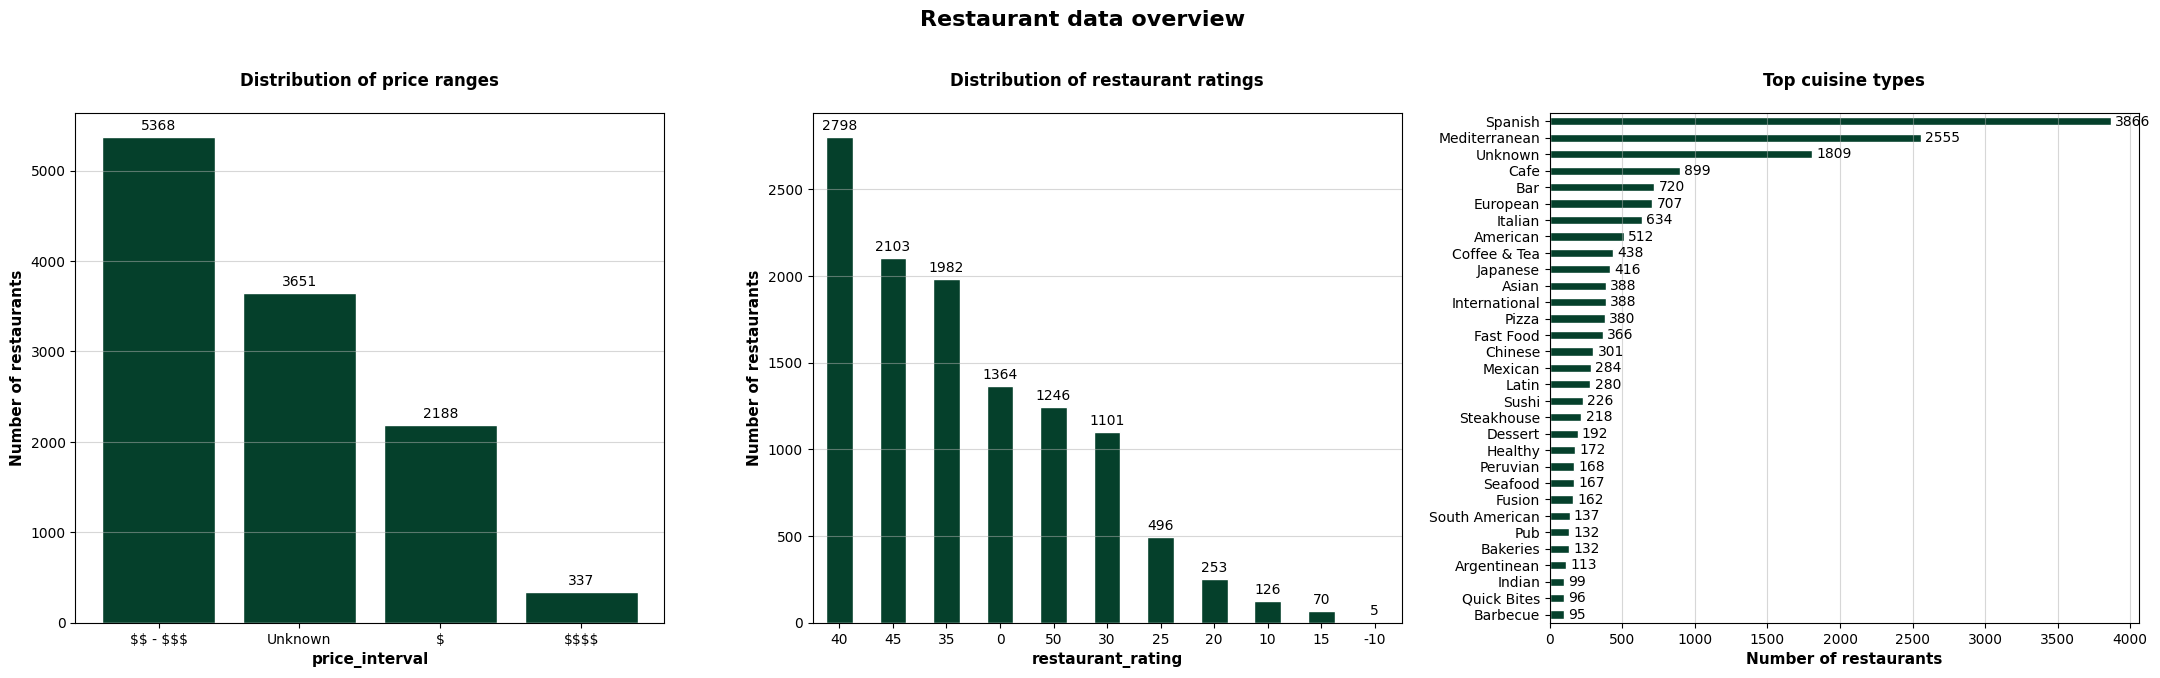

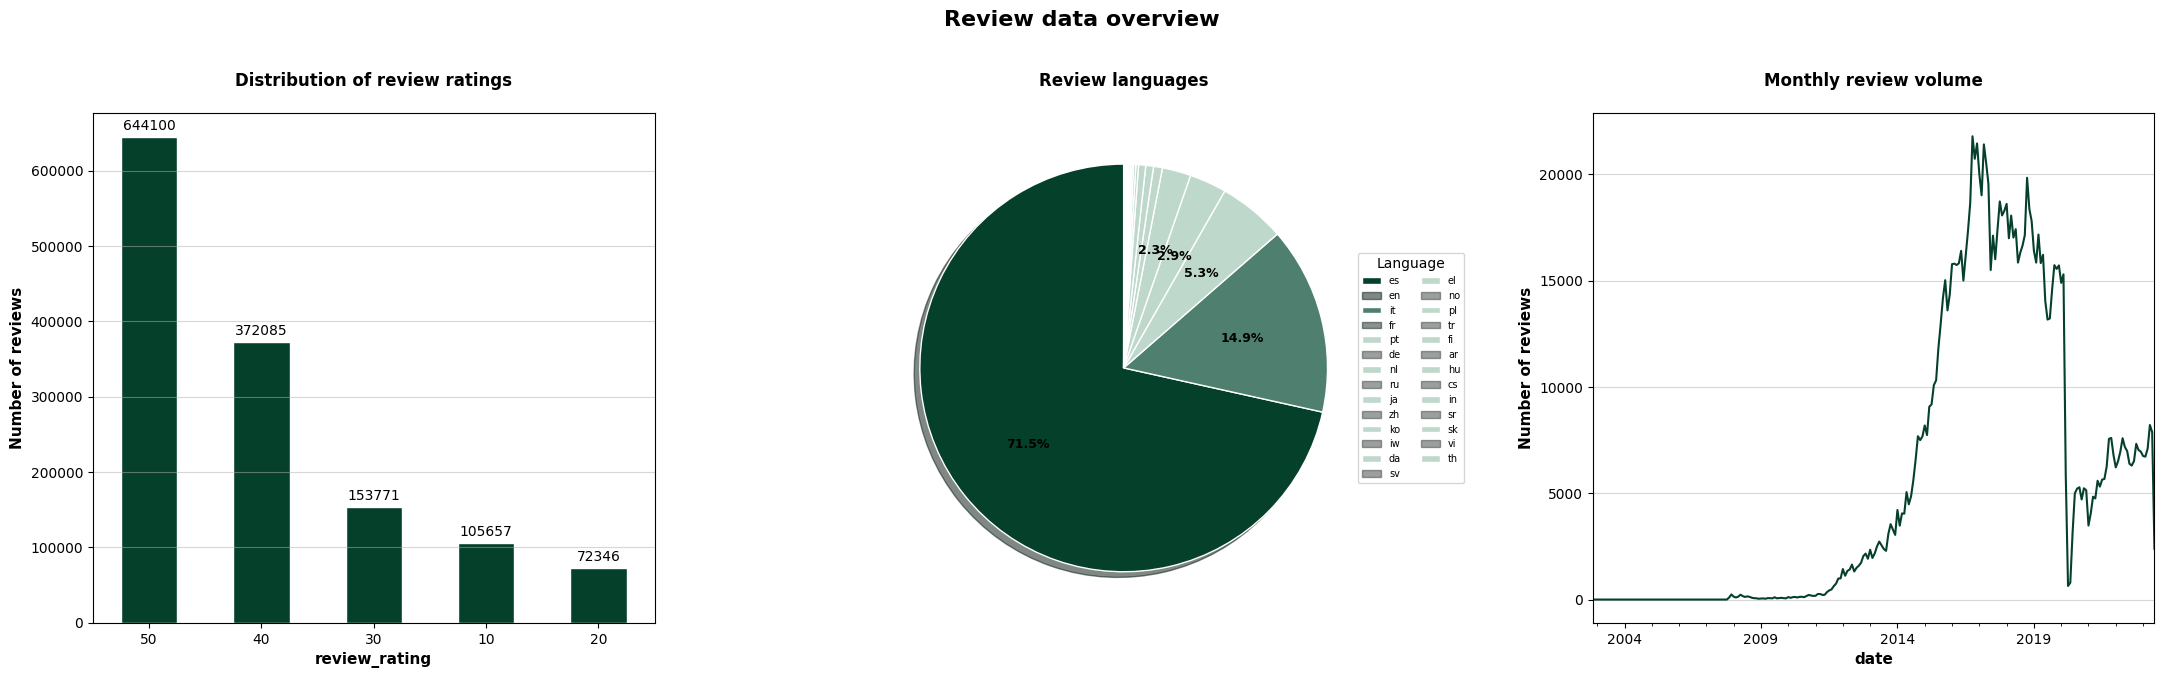

In [11]:

# Explore restaurant data with charts
fig, axes = plt.subplots(1, 3, figsize=(22, 7))

# Price ranges
price_counts = (
    items['price_interval']
    .astype('string')
    .str.strip()
    .replace('', 'Unknown')
    .fillna('Unknown')
    .value_counts()
)

price_labels = [str(value).replace('$', r'\$') for value in price_counts.index]

axes[0].bar(
    price_labels,
    price_counts.values,
    color='#05402B',
    edgecolor='white'
)

format_axis(
    axes[0],
    'Distribution of price ranges',
    'price_interval',
    'Number of restaurants'
)
add_bar_labels(axes[0])

# Restaurant rating
restaurant_rating_plot = (
    items['restaurant_rating']
    .value_counts()
    .plot(kind='bar', ax=axes[1], color='#05402B', edgecolor='white')
)

format_axis(
    axes[1],
    'Distribution of restaurant ratings',
    'restaurant_rating',
    'Number of restaurants'
)
axes[1].tick_params(axis='x', rotation=0)
add_bar_labels(axes[1])

# Cuisine types
type_counts = (
    items['type']
    .explode()
    .astype('string')
    .str.strip()
    .replace('', pd.NA)
    .fillna('Unknown')
    .value_counts()
)

type_top = type_counts[type_counts.index != 'Unknown'].head(30)

if 'Unknown' in type_counts.index:
    type_top = pd.concat([
        type_top,
        type_counts[type_counts.index == 'Unknown']
    ])

type_top.sort_values().plot(
    kind='barh',
    ax=axes[2],
    color='#05402B',
    edgecolor='white'
)

format_axis(
    axes[2],
    'Top cuisine types',
    'Number of restaurants',
    '',
    'x'
)
add_bar_labels(axes[2])

fig.suptitle(
    'Restaurant data overview',
    fontsize=16,
    fontweight='bold'
)

fig.tight_layout(pad=2)
plt.show()



# Explore reviews with charts
fig, axes = plt.subplots(1, 3, figsize=(22, 7))

# Ratings
review_rating_plot = (
    reviews['review_rating']
    .value_counts()
    .plot(kind='bar', ax=axes[0], color='#05402B', edgecolor='white')
)

format_axis(
    axes[0],
    'Distribution of review ratings',
    'review_rating',
    'Number of reviews'
)
axes[0].tick_params(axis='x', rotation=0)
add_bar_labels(axes[0])

# Languages
language_counts = reviews['language'].value_counts()

color_map = {
    'es': '#05402B',
    'en': '#4F7F6E'
}

language_colors = [
    color_map.get(language, '#BFD8CC')
    for language in language_counts.index
]

language_plot = language_counts.plot(
    kind='pie',
    ax=axes[1],
    labels=None,
    colors=language_colors,
    autopct=lambda percentage: f'{percentage:.1f}%' if percentage >= 1 else '',
    startangle=90,
    shadow=True,
    wedgeprops={'edgecolor': 'white', 'linewidth': 1},
    textprops={'fontsize': 9, 'fontweight': 'bold'}
)

language_plot.set_ylabel('')
language_plot.set_title(
    'Review languages',
    fontsize=12,
    fontweight='bold',
    pad=20
)

language_plot.legend(
    language_plot.patches,
    language_counts.index.astype(str),
    title='Language',
    loc='center left',
    bbox_to_anchor=(0.95, 0.5),
    fontsize=7,
    ncol=2
)

# Changes over time
monthly_reviews_plot = (
    reviews
    .groupby(reviews['date'].dt.to_period('M'))
    .size()
    .plot(kind='line', ax=axes[2], color='#05402B')
)

format_axis(
    axes[2],
    'Monthly review volume',
    'date',
    'Number of reviews'
)

fig.suptitle(
    'Review data overview',
    fontsize=16,
    fontweight='bold'
)

fig.tight_layout(pad=2)
plt.show()

The charts help us check data quality visually.


## 1.4. Find incorrectly coded values

These are counts **before** removing duplicate rows:

- `user_id`: 6,123 values of `-1`; keep the reviews and mark these IDs as missing.
- `price_interval`: 3,651 empty strings (31.6%).
- `type`: 1,809 empty lists (15.7%).
- `title`: 14 empty strings and five titles containing only exclamation marks; mark them as missing.
- `text`: no reported missing values; repeated text does not prove duplication.


## 1.5. Find values outside the expected range

- `review_rating`: observed scores range from 10 to 50 in steps of 10.
- `restaurant_rating`: treat `0` as missing. Treat the five `-10` values as missing too: one customer's score cannot replace a restaurant-level rating.
- Divide valid ratings by 10 to express them on a 1-to-5 scale.
- `date`: no invalid dates. Early review volume is low, activity falls in 2020, and June 2023 is incomplete.


In [12]:
# Check invalid dates and the date range
print('Invalid dates:', reviews['date'].isna().sum())
print('Earliest date:', reviews['date'].min())
print('Latest date:', reviews['date'].max())

Invalid dates: 0
Earliest date: 2002-11-11 00:00:00
Latest date: 2023-06-10 00:00:00


## 1.6. Review categories and small groups

- `price_interval`: rename `$`, `$$ - $$$`, and `$$$$` as Budget, Mid-range, and Premium.
- Premium includes 337 restaurants (2.9%). It is a small but valid group.
- `type`: use `explode()` and check group size before benchmarking.
- `review_rating`: 75.4% of reviews have a score of 4 or 5; account for class imbalance during splitting, training, and evaluation.
- Sentiment: 1 and 2 = Negative; 3 = Neutral; 4 and 5 = Positive.
- `language`: Spanish and English account for 86.4% of reviews; keep both for the bilingual classifier.


## 1.7. Check duplicates


In [13]:
items_hashable = items.assign(type=items['type'].apply(lambda v: tuple(v) if isinstance(v, list) else v))

print('Reviews:', reviews.duplicated().sum())
print('Items:', items_hashable.duplicated().sum())

Reviews: 8608
Items: 76


## 1.8. Check the join between datasets


In [14]:
# Check the relationship using item_id
print('Reviews without a restaurant:',
    (~reviews['item_id'].isin(items['item_id'])).sum())

print('Restaurants without reviews:',
    (~items['item_id'].isin(reviews['item_id'])).sum())

Reviews without a restaurant: 0
Restaurants without reviews: 1364


**Relationship between datasets**

- Every review `item_id` exists in `items`.
- Before duplicate removal, 1,364 restaurant rows have no reviews. After removing duplicate rows, the count is 1,359 restaurants.
- Use an `inner` join and validate it as `many_to_one`.


## 1.9. Check missing values


`info()` does not detect missing values stored as `-1`, empty strings, or empty lists. This check identifies them.


In [15]:
# Check coded missing values
print('Identified missing values')
print('user_id equal to -1:', reviews['user_id'].eq('-1').sum())
print('Empty titles:', reviews['title'].str.strip().eq('').sum())
print('Titles containing only !:', reviews['title'].str.strip().eq('!').sum())
print('Empty price ranges:', items['price_interval'].astype('string').str.strip().eq('').sum())
print('Empty cuisine lists:', items['type'].apply(len).eq(0).sum())

Identified missing values
user_id equal to -1: 6123
Empty titles: 14
Titles containing only !: 5
Empty price ranges: 3651
Empty cuisine lists: 1809


# 2. Data cleaning and basic preparation


## 2.1. Correct data types


In [16]:
print("Review data types")
display(reviews.dtypes)
print("\nRestaurant data types")
display(items.dtypes)

Review data types


review_id        string[python]
user_id          string[python]
item_id          string[python]
title            string[python]
text             string[python]
date             datetime64[ns]
review_rating             Int64
language               category
dtype: object


Restaurant data types


item_id              string[python]
name                 string[python]
price_interval             category
restaurant_rating             Int64
type                         object
dtype: object

The data types are correct. Change `restaurant_rating` to `Float64` to allow decimal values.


In [17]:
# Allow decimal restaurant ratings
items['restaurant_rating'] = items['restaurant_rating'].astype('Float64')

## 2.2. Correct incorrectly coded values


In [18]:
# Mark unknown user IDs as missing
reviews['user_id'] = reviews['user_id'].mask(reviews['user_id'] == '-1')

In [19]:
# Remove uninformative titles
reviews['title'] = reviews['title'].str.strip()
reviews['title'] = reviews['title'].mask(reviews['title'].str.fullmatch(r'[¡!]*', na=False))

In [20]:
# Mark empty price ranges as missing
items['price_interval'] = (items['price_interval'].astype('string').str.strip())
items['price_interval'] = items['price_interval'].mask(items['price_interval'] == '')

In [21]:
# Mark empty cuisine lists as missing
empty_type_mask = items['type'].apply(
    lambda value: isinstance(value, list) and len(value) == 0
)
items['type'] = items['type'].mask(empty_type_mask)

In [22]:
# Check zero ratings
restaurant_has_reviews = items['item_id'].isin(reviews['item_id'])
zero_rating_mask = items['restaurant_rating'].eq(0)

zero_ratings_with_reviews = (zero_rating_mask & restaurant_has_reviews).sum()
print('Restaurants rated 0 with reviews:', zero_ratings_with_reviews)

if zero_ratings_with_reviews != 0:
    raise ValueError('Some restaurants have a rating of 0 but also have reviews.')

# Mark zero ratings as missing
items['restaurant_rating'] = items['restaurant_rating'].mask(zero_rating_mask)

Restaurants rated 0 with reviews: 0


## 2.3. Correct values outside the expected range


In [23]:
# Mark invalid restaurant ratings as missing
invalid_rating_mask = items['restaurant_rating'].eq(-10).fillna(False)
invalid_restaurant_ids = items.loc[invalid_rating_mask, 'item_id']

print('Invalid restaurant ratings:', int(invalid_rating_mask.sum()))
print('Affected restaurant IDs:', invalid_restaurant_ids.tolist())

# A review score is not a replacement for the restaurant's overall rating
items['restaurant_rating'] = items['restaurant_rating'].mask(invalid_rating_mask)


Invalid restaurant ratings: 5
Affected restaurant IDs: ['25971804', '26177921', '26193489', '26028983', '26193231']


In [24]:
# Express ratings on a 1-to-5 scale
items['restaurant_rating'] = (items['restaurant_rating'] / 10).astype('Float64')
reviews['review_rating'] = (reviews['review_rating'] / 10).astype('Int64')


## 2.4. Standardize categories


In [25]:
# Standardize price ranges
items['price_interval'] = pd.Categorical(
    items['price_interval'].map({
        '$': 'Budget',
        '$$ - $$$': 'Mid-range',
        '$$$$': 'Premium'
    }),
    categories=['Budget', 'Mid-range', 'Premium'],
    ordered=True
)

## 2.5. Handle duplicates


In [26]:
# Remove fully duplicated review rows
reviews.drop_duplicates(inplace=True)

# Temporarily convert cuisine lists to check duplicates
items_hashable = items.assign(
    type=items['type'].apply(
        lambda value: (
            tuple(value)
            if isinstance(value, list)
            else value
        )
    )
)

# Remove fully duplicated restaurant rows
items.drop(index=items.index[items_hashable.duplicated()],inplace=True)

In [27]:
print("Total duplicates")
print(f"Reviews: {reviews.duplicated('review_id').sum()}")
print(f"Items: {items.duplicated('item_id').sum()}")

Total duplicates
Reviews: 0
Items: 0


## 2.6. Select relevant variables


In [28]:
# Keep Spanish and English reviews and remove user_id
# The source language code describes the review metadata; some reviews mix languages
reviews = (
    reviews.loc[
        reviews['language'].isin(['es', 'en'])
    ]
    .drop(columns='user_id', errors='ignore')
)

reviews['language'] = reviews['language'].cat.remove_unused_categories()


In [29]:
# Create and validate the sentiment target
sentiment_map = {
    1: 'Negative',
    2: 'Negative',
    3: 'Neutral',
    4: 'Positive',
    5: 'Positive'
}

reviews['sentiment'] = pd.Categorical(
    reviews['review_rating'].map(sentiment_map),
    categories=[
        'Negative',
        'Neutral',
        'Positive'
    ],
    ordered=True
)

if reviews['sentiment'].isna().any():
    unexpected_ratings = reviews.loc[
        reviews['sentiment'].isna(),
        'review_rating'
    ].unique()
    raise ValueError(f'Ratings without a sentiment class: {unexpected_ratings}')

- Remove `user_id` after the data quality checks.
- Keep records labeled Spanish or English in the source. A review may contain words from both languages; the language code is not a sentence-by-sentence language check.
- `sentiment` is the target variable.
- Keep `review_rating` for traceability, but exclude it as a model feature because it determines `sentiment`.
- Use `restaurant_rating` for diagnosis and benchmarking when available, but exclude it as a model feature to prevent data leakage.


## 2.7. Handle missing values


In [30]:
# Check remaining missing values
print("\nMissing values in reviews")
display(reviews.isna().sum())
print("\nMissing values in restaurants")
display(items.isna().sum())


Missing values in reviews


review_id         0
item_id           0
title            17
text              0
date              0
review_rating     0
language          0
sentiment         0
dtype: int64


Missing values in restaurants


item_id                 0
name                    0
price_interval       3632
restaurant_rating    1364
type                 1800
dtype: int64

**Reviews**

- `user_id` has already been removed.
- After duplicate removal and title cleaning, fill the 17 missing `title` values with empty strings.

**Items**

- After removing duplicate rows, 3,632 `price_interval` values are missing. Label them `Unknown`; their prices remain unknown.
- After removing duplicate rows, 1,800 `type` values are missing. Label them `['Unknown']`; their cuisine types remain unknown.
- After duplicate removal, 1,359 restaurants have no reviews and are excluded by the `inner` join.
- Five additional restaurants have an invalid original rating (`-10`). Their ratings remain missing even when their reviews are included.

These counts refer to different cleaning stages; `Unknown` is a missing-data label, not a price or cuisine type.


In [31]:
# Fill missing titles
reviews['title'] = reviews['title'].fillna('')

In [32]:
# Label missing price ranges
items['price_interval'] = pd.Categorical(
    items['price_interval']
    .astype('string')
    .fillna('Unknown'),
    categories=[
        'Budget',
        'Mid-range',
        'Premium',
        'Unknown'
    ],
    ordered=False
)

In [33]:
# Label missing cuisine types
items['type'] = items['type'].apply(
    lambda value: (
        value
        if isinstance(value, list)
        else ['Unknown']
    )
)

## 2.8. Join reviews and restaurants


In [34]:
# Join reviews and restaurants
data = reviews.merge(
    items,
    on='item_id',
    how='inner',
    validate='many_to_one'
)

print('Reviews removed by the join:', len(reviews) - len(data))

Reviews removed by the join: 0


## 2.9. Final checks


In [35]:
# Check the final dataset
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1157800 entries, 0 to 1157799
Data columns (total 12 columns):
 #   Column             Non-Null Count    Dtype         
---  ------             --------------    -----         
 0   review_id          1157800 non-null  string        
 1   item_id            1157800 non-null  string        
 2   title              1157800 non-null  string        
 3   text               1157800 non-null  string        
 4   date               1157800 non-null  datetime64[ns]
 5   review_rating      1157800 non-null  Int64         
 6   language           1157800 non-null  category      
 7   sentiment          1157800 non-null  category      
 8   name               1157800 non-null  string        
 9   price_interval     1157800 non-null  category      
 10  restaurant_rating  1157795 non-null  Float64       
 11  type               1157800 non-null  object        
dtypes: Float64(1), Int64(1), category(3), datetime64[ns](1), object(1), string(5)
memory

The final dataset contains 1,157,800 rows and 12 variables. Missing restaurant ratings remain missing; check the updated counts in the output above.


In [36]:
# Validate every exported column
schema = pa.DataFrameSchema({
    'review_id': pa.Column(str, unique=True, nullable=False),
    'item_id': pa.Column(str, nullable=False),
    'title': pa.Column(str, nullable=False),
    'text': pa.Column(str, nullable=False),
    'date': pa.Column('datetime64[ns]', nullable=False),
    'review_rating': pa.Column(int, checks=pa.Check.in_range(1, 5), nullable=False),
    'language': pa.Column(str, checks=pa.Check.isin(['es', 'en']), nullable=False),
    'sentiment': pa.Column(str, checks=pa.Check.isin(['Negative', 'Neutral', 'Positive']), nullable=False),
    'name': pa.Column(str, nullable=False),
    'price_interval': pa.Column(str, checks=pa.Check.isin(['Budget', 'Mid-range', 'Premium', 'Unknown']), nullable=False),
    'restaurant_rating': pa.Column(pd.Float64Dtype(), checks=pa.Check.in_range(1, 5), nullable=True),
    'type': pa.Column(object, checks=pa.Check(lambda s: s.map(lambda v: isinstance(v, list) and len(v) > 0)), nullable=False),
}, strict=True)

schema.validate(data, lazy=True)

# Check the relationship between the score and target label
expected_sentiment = data['review_rating'].map(sentiment_map).astype('string')
if not data['sentiment'].astype('string').eq(expected_sentiment).all():
    raise ValueError('Some sentiment labels do not match their review ratings.')

print('Rows:', len(data))
print('Missing restaurant ratings:', int(data['restaurant_rating'].isna().sum()))
print('Restaurants with missing ratings:', data.loc[data['restaurant_rating'].isna(), 'item_id'].nunique())


Rows: 1157800
Missing restaurant ratings: 5
Restaurants with missing ratings: 5


All exported columns have been checked against the schema, and sentiment labels match their review ratings. Missing restaurant ratings are reported above.


**Export the cleaned data**


In [37]:
# Save as Pickle
OUTPUT_PATH = DATA_PATH / 'data_processed.pkl'
data.to_pickle(OUTPUT_PATH)
print(f'Data saved to: {OUTPUT_PATH.resolve()}')

# Save as Parquet
data.to_parquet(
    DATA_PATH / 'data_processed.parquet',
    index=False
)

Data saved to: /Users/carolina/1.Restaurant_intelligence/data/data_processed.pkl
